# Netflix Movies & TV Shows — Exploratory Data Analysis

**Project type:** Beginner Data Analytics project  
**Tools:** Python, Pandas, Matplotlib, Seaborn

## 1. Project Overview
This project explores the Netflix Movies and TV Shows dataset to understand the content available on Netflix. It uses basic data cleaning, descriptive statistics, and visualizations to identify patterns in content type, release years, countries, genres, ratings, directors, and content additions.

### Questions explored
- How many Movies and TV Shows are in the dataset?
- Which release years have the most titles?
- Which country entries and genre combinations appear most often?
- Which ratings are most common?
- How are TV Shows distributed by number of seasons?
- Which directors have the most listed titles?
- When was content most frequently added to Netflix?

> **Note:** In this dataset, `country`, `listed_in`, and `director` can contain multiple comma-separated values. The simple `value_counts()` charts below count the full text entry as one category. They do not split each country, genre, or director into separate values.

## 2. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent chart style
sns.set_theme(style="whitegrid")

## 3. Load the Dataset

Keep `netflix_titles.csv` in the same folder as this notebook. If your file is stored elsewhere, update the path.

In [2]:
df = pd.read_csv("netflix_titles.csv", encoding="unicode_escape")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 4. Understand the Dataset

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 3.9 MB


In [4]:
# Check column names
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [5]:
# Summary of numeric columns
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


In [6]:
# Check missing values before cleaning
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

## 5. Data Cleaning

For categorical columns, missing values are replaced with `Unknown`. Missing `date_added` values are kept as `NaT` after conversion so date-based analysis works correctly.

In [7]:
# Fill missing values in selected columns
df["director"] = df["director"].fillna("Unknown")
df["cast"] = df["cast"].fillna("Unknown")
df["country"] = df["country"].fillna("Unknown")
df["date_added"] = df["date_added"].fillna("Unknown")
df["duration"] = df["duration"].fillna("Unknown")

# Convert date_added to datetime
df["date_added"] = pd.to_datetime(
    df["date_added"].replace("Unknown", pd.NA),
    errors="coerce"
)

# Check missing values after cleaning
df.isnull().sum()

show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      98
release_year     0
rating           4
duration         0
listed_in        0
description      0
dtype: int64

In [8]:
# Check data types after cleaning
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   show_id       8807 non-null   str           
 1   type          8807 non-null   str           
 2   title         8807 non-null   str           
 3   director      8807 non-null   str           
 4   cast          8807 non-null   str           
 5   country       8807 non-null   str           
 6   date_added    8709 non-null   datetime64[us]
 7   release_year  8807 non-null   int64         
 8   rating        8803 non-null   str           
 9   duration      8807 non-null   str           
 10  listed_in     8807 non-null   str           
 11  description   8807 non-null   str           
dtypes: datetime64[us](1), int64(1), str(10)
memory usage: 3.8 MB


## 6. Basic Dataset Exploration

In [9]:
print("Total rows:", len(df))
print("Unique titles:", df["title"].nunique())
print("Unique country entries:", df["country"].nunique())
print("Unique genre entries:", df["listed_in"].nunique())
print("Unique director entries:", df["director"].nunique())
print("Unique ratings:", df["rating"].nunique())

Total rows: 8807
Unique titles: 8807
Unique country entries: 749
Unique genre entries: 514
Unique director entries: 4529
Unique ratings: 17


### Content type count

In [10]:
type_counts = df["type"].value_counts()
print(type_counts)

type
Movie      6131
TV Show    2676
Name: count, dtype: int64


**Observation:** The Netflix catalogues has more Movies than TV-Shows in the dataset.

## 7. Exploratory Data Analysis (EDA)

### 7.1 Movies vs TV Shows
**Question:** Which content type is more common in the dataset?

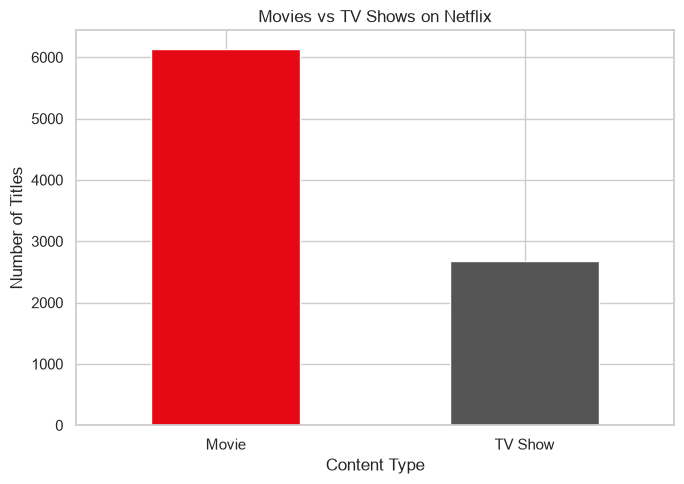

In [11]:
type_counts = df["type"].value_counts()

plt.figure(figsize=(7, 5))
type_counts.plot(kind="bar", color=["#E50914", "#555555"])
plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

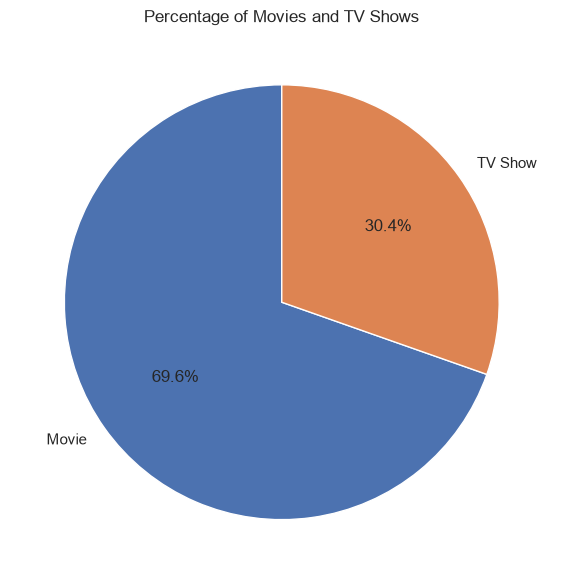

In [12]:
plt.figure(figsize=(6, 6))
type_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90)
plt.title("Percentage of Movies and TV Shows")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Observation / Insight:** Dataset has 69.6% perecent movies and 30.4% TV-Shows. That shows Movie is most common in the dataset.

### 7.2 Content Released by Year
**Question:** How many titles were released in each year, and which year has the most releases?

<Figure size 1200x600 with 0 Axes>

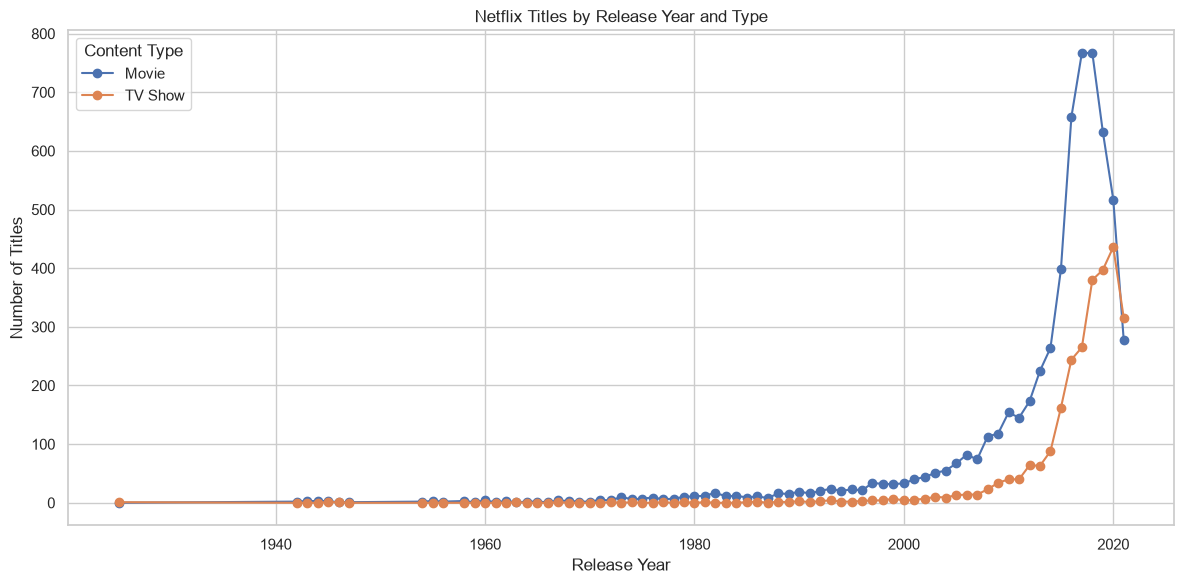

In [13]:
yearly_data = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)

plt.figure(figsize=(12, 6))
yearly_data.plot(kind="line", figsize=(12, 6), marker="o")
plt.title("Netflix Titles by Release Year and Type")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

Year with the most releases: 2018
Number of titles released: 1147


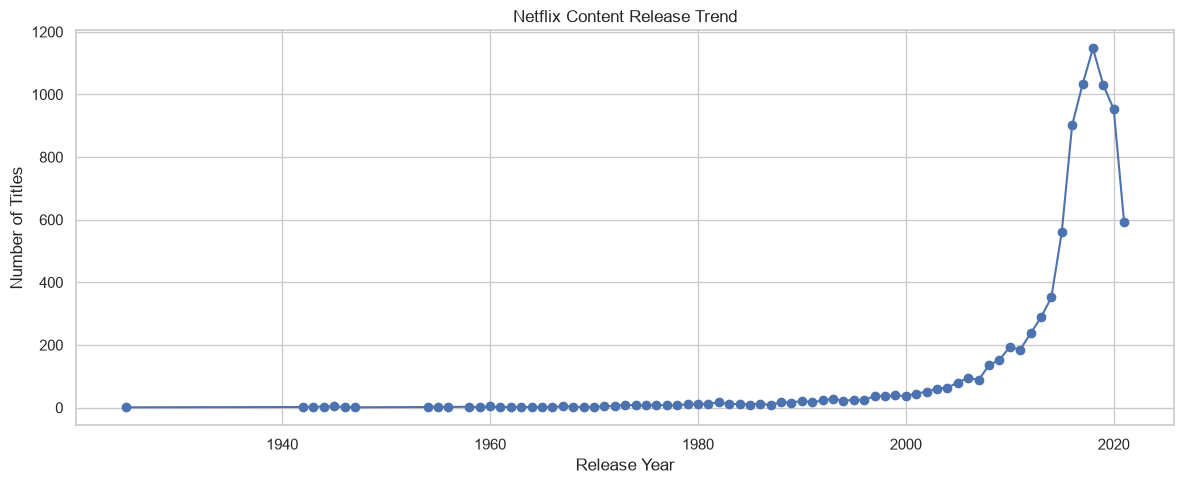

In [14]:
yearly_total = df["release_year"].value_counts().sort_index()

highest_release_year = yearly_total.idxmax()
highest_release_count = yearly_total.max()

print("Year with the most releases:", highest_release_year)
print("Number of titles released:", highest_release_count)

plt.figure(figsize=(12, 5))
yearly_total.plot(kind="line", marker="o")
plt.title("Netflix Content Release Trend")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

**Observation / Insight:** 2018 year has the highest release count and from 2019 it started to fall the release count slightly.

### 7.3 Top 10 Country Entries
**Question:** Which country entries appear most frequently?

> This simple chart counts combined country strings (for example, `India, United States`) as one entry. It is not an individual-country ranking.

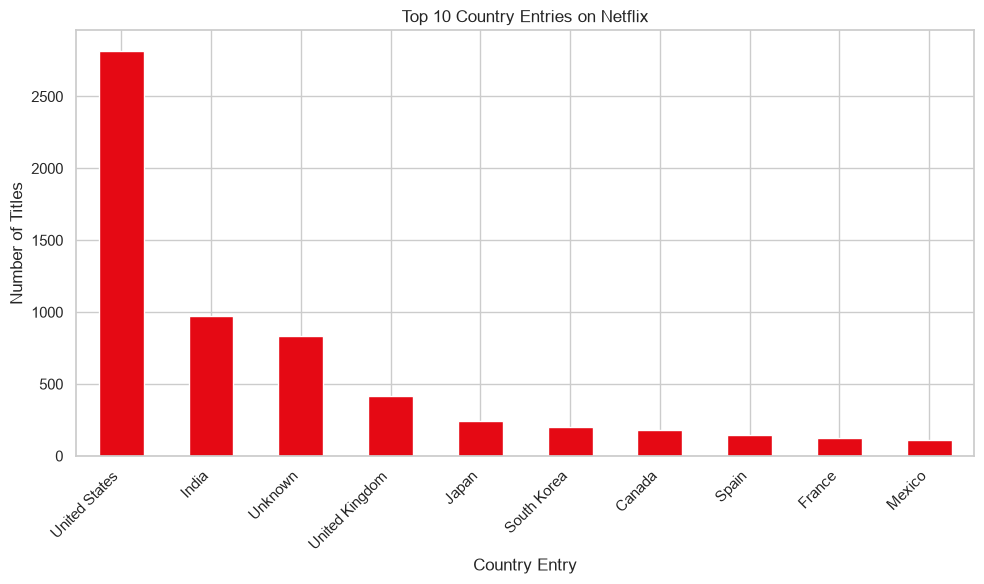

country
United States     2818
India              972
Unknown            831
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Name: count, dtype: int64


In [15]:
top_country_entries = df["country"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_country_entries.plot(kind="bar", color="#E50914")
plt.title("Top 10 Country Entries on Netflix")
plt.xlabel("Country Entry")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(top_country_entries)

**Observation / Insight:** United State is the most frequent country entry. 

### 7.4 Top 10 Genre Entries
**Question:** Which genre combinations appear most frequently?

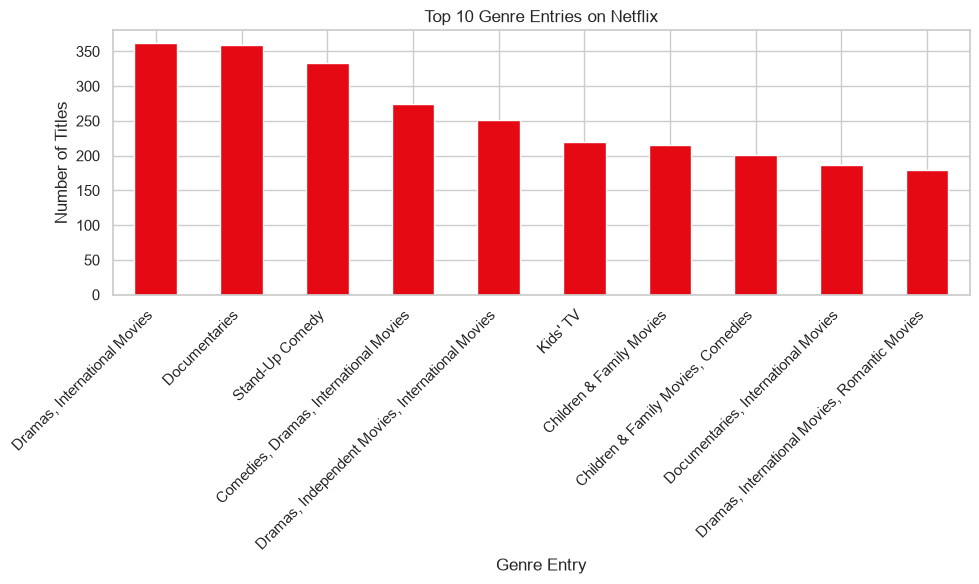

listed_in
Dramas, International Movies                        362
Documentaries                                       359
Stand-Up Comedy                                     334
Comedies, Dramas, International Movies              274
Dramas, Independent Movies, International Movies    252
Kids' TV                                            220
Children & Family Movies                            215
Children & Family Movies, Comedies                  201
Documentaries, International Movies                 186
Dramas, International Movies, Romantic Movies       180
Name: count, dtype: int64


In [16]:
top_genres = df["listed_in"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_genres.plot(kind="bar", color="#E50914")
plt.title("Top 10 Genre Entries on Netflix")
plt.xlabel("Genre Entry")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(top_genres)

**Observation / Insight:** Dramas, International Movies is the most common genre entry. 

### 7.5 Content Rating Distribution
**Question:** Which content rating is most common?

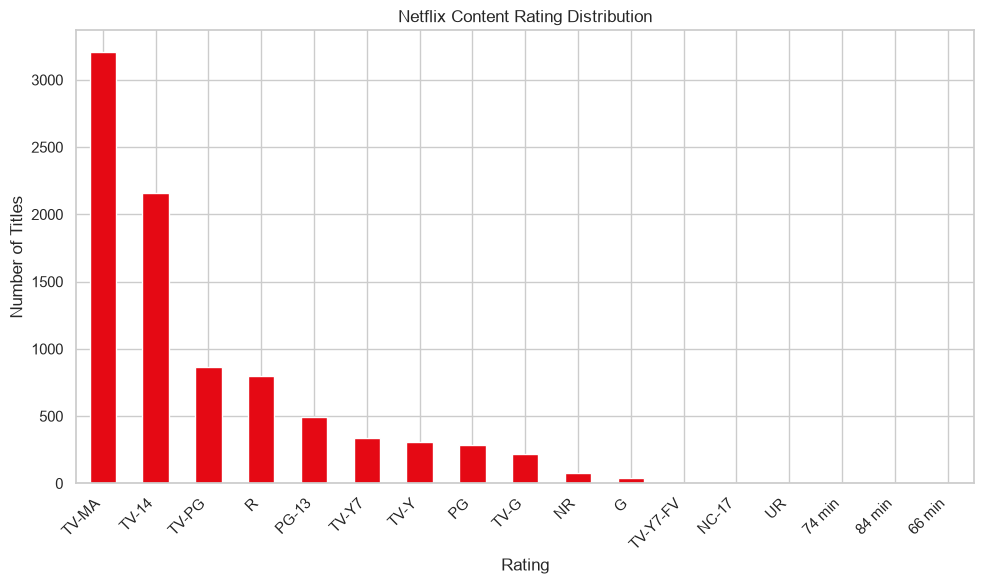

Most common rating: TV-MA
Number of titles: 3207


In [17]:
rating_counts = df["rating"].value_counts()

plt.figure(figsize=(10, 6))
rating_counts.plot(kind="bar", color="#E50914")
plt.title("Netflix Content Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Most common rating:", rating_counts.idxmax())
print("Number of titles:", rating_counts.max())

**Observation / Insight:** TV-MA is the most frequent rating and indicating a significant presence of mature-audience content in the catalogue.

### 7.6 TV Shows by Number of Seasons
**Question:** How many TV Shows have one season, two seasons, and so on?

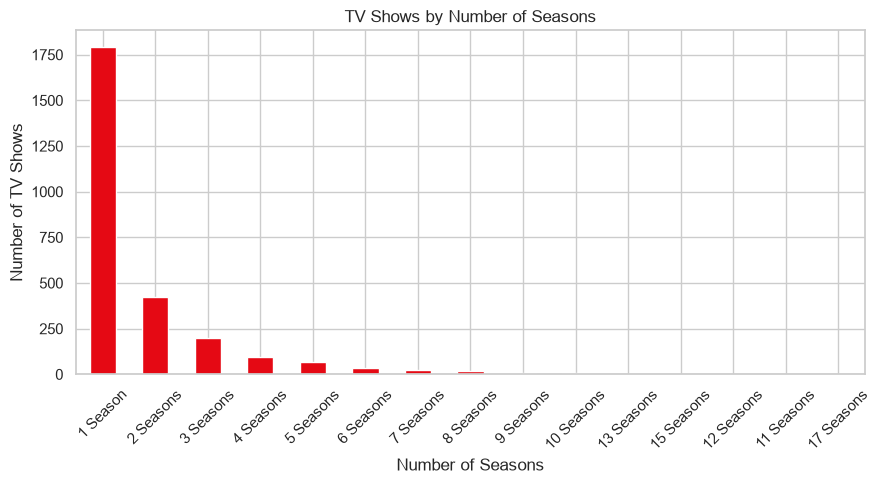

duration
1 Season      1793
2 Seasons      425
3 Seasons      199
4 Seasons       95
5 Seasons       65
6 Seasons       33
7 Seasons       23
8 Seasons       17
9 Seasons        9
10 Seasons       7
13 Seasons       3
15 Seasons       2
12 Seasons       2
11 Seasons       2
17 Seasons       1
Name: count, dtype: int64


In [18]:
tv_shows = df[df["type"] == "TV Show"]

season_counts = tv_shows["duration"].value_counts()

plt.figure(figsize=(9, 5))
season_counts.plot(kind="bar", color="#E50914")
plt.title("TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(season_counts)

**Observation / Insight:** The most common season count is 1 Season. 

### 7.7 Top 10 Directors
**Question:** Which directors have the most titles listed?

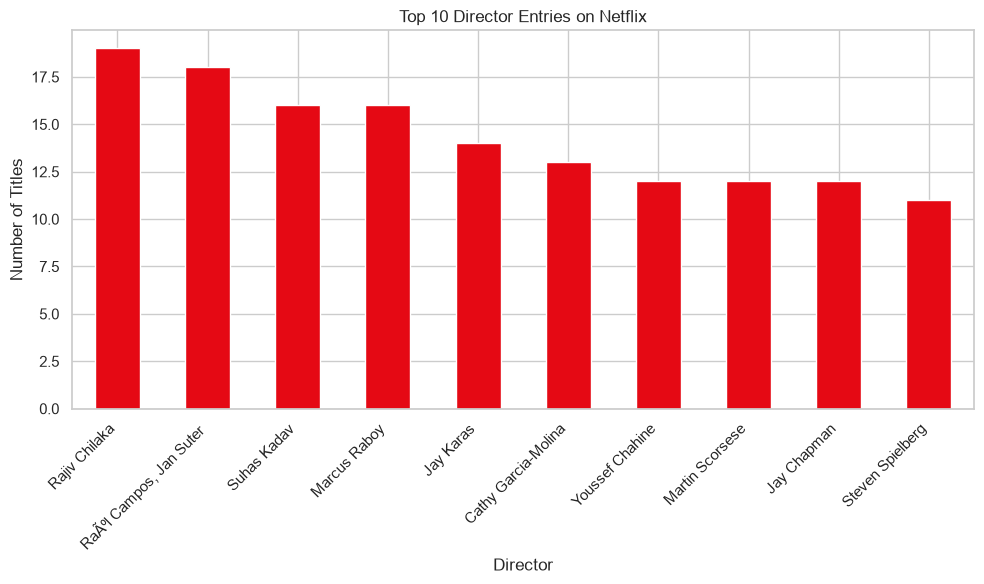

director
Rajiv Chilaka              19
RaÃºl Campos, Jan Suter    18
Suhas Kadav                16
Marcus Raboy               16
Jay Karas                  14
Cathy Garcia-Molina        13
Youssef Chahine            12
Martin Scorsese            12
Jay Chapman                12
Steven Spielberg           11
Name: count, dtype: int64


In [19]:
known_directors = df[df["director"] != "Unknown"]

top_directors = known_directors["director"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_directors.plot(kind="bar", color="#E50914")
plt.title("Top 10 Director Entries on Netflix")
plt.xlabel("Director")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print(top_directors)

**Observation / Insight:** Rajiv Chilaka is the leading director entry. Some rows may list multiple directors together, so this chart counts a combined entry as one.

### 7.8 Content Added by Year
**Question:** In which year was the most content added to Netflix?

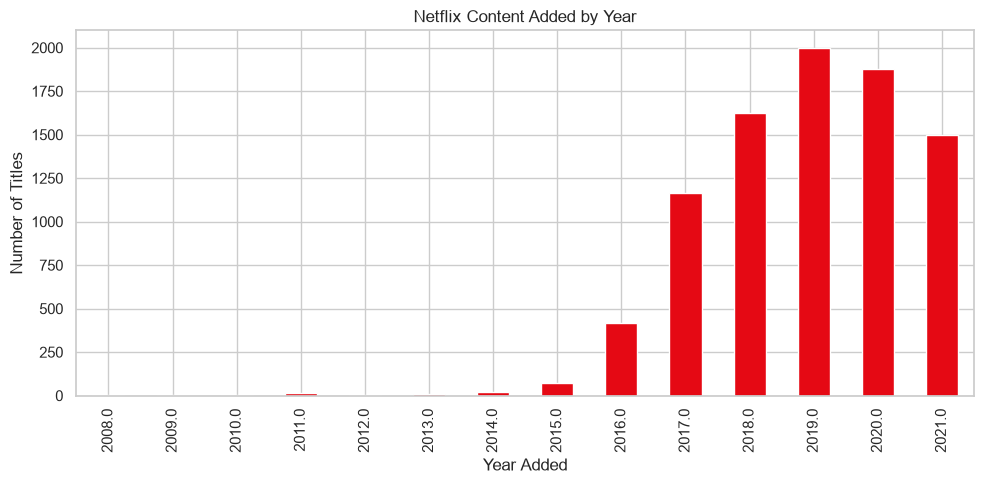

Year with the most additions: 2019.0
Number of titles added: 1999


In [20]:
added_by_year = df["date_added"].dt.year.value_counts().sort_index()

plt.figure(figsize=(10, 5))
added_by_year.plot(kind="bar", color="#E50914")
plt.title("Netflix Content Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

print("Year with the most additions:", added_by_year.idxmax())
print("Number of titles added:", added_by_year.max())

**Observation / Insight:** 2019 is the year with the most additions. This measures when titles were added to Netflix, not when they were originally released.

### 7.9 Content Added by Month
**Question:** In which month was the most content added?

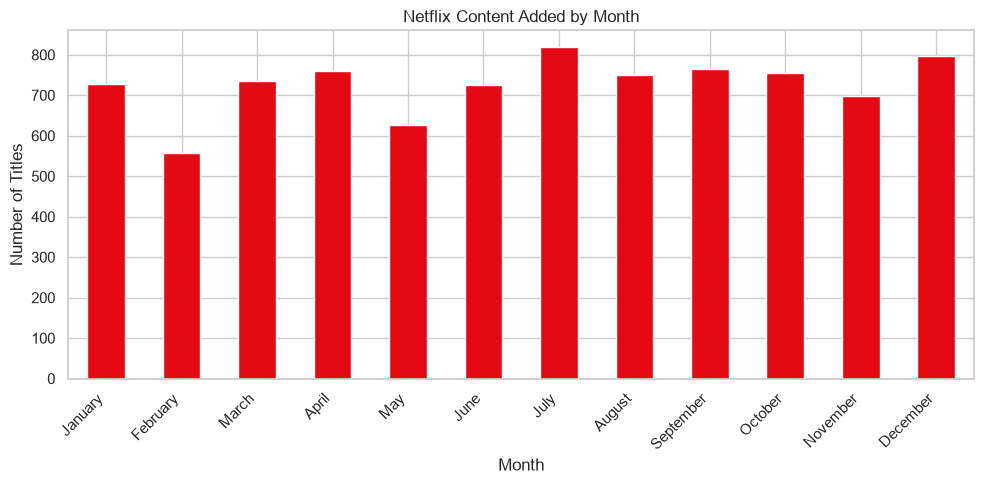

Month with the most additions: July
Number of titles added: 819


In [21]:
month_order = [
    "January", "February", "March", "April", "May", "June",
    "July", "August", "September", "October", "November", "December"
]

added_by_month = df["date_added"].dt.month_name().value_counts().reindex(month_order, fill_value=0)

plt.figure(figsize=(10, 5))
added_by_month.plot(kind="bar", color="#E50914")
plt.title("Netflix Content Added by Month")
plt.xlabel("Month")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

print("Month with the most additions:", added_by_month.idxmax())
print("Number of titles added:", added_by_month.max())

**Observation / Insight:** July month is the month with the highest number of additions. 

## 8. Key Findings

Complete these points after running all cells. Use numbers from your outputs; do not copy example values without checking them.

1. **Content type:** Movies / TV Shows are more common (include counts or percentages).
2. **Release trend:** The release year with the highest number of titles is **2019**.
3. **Country entry:** The most frequent country entry is **United State**.
4. **Genre entry:** The most frequent genre entry is **Drama, Internation Movies**.
5. **Rating:** The most common rating is **TV-MA(Mature Audience Only)**.
6. **TV Show seasons:** The most common season count is **1 Season**.
7. **Director:** The director entry with the most titles is **Rajiv Chilaka**.
8. **Content addition:** The month with the most additions is **January**.

## 9. Conclusion

This project used Python and Pandas to clean and explore the Netflix Movies and TV Shows dataset. Matplotlib was used to create visualizations of content type, release trends, country and genre entries, ratings, TV Show seasons, directors, and content additions. The analysis helped summarize patterns in the dataset and practice data cleaning, exploratory analysis, and data visualization.

## 10. Limitations

- Country, genre, and director columns may contain multiple comma-separated values. Basic `value_counts()` counts combined entries rather than individual names.
- The dataset represents the catalogue captured in the source file; it should not be treated as a live Netflix catalogue.
- Findings describe patterns in this dataset and do not establish why Netflix made content decisions.